# 🔀 Logistic Regression from Scratch

**Goal:** Predict the probability that an example belongs to one of two classes (binary classification).

---

## 1. Algorithm Intuition

Logistic Regression is a **linear classifier**: it computes a linear score, then squashes it through the **sigmoid** function to produce a probability between 0 and 1.

**Step 1 — Linear score:**
$$z^{(i)} = \mathbf{w}^T \mathbf{x}^{(i)} + b$$

**Step 2 — Sigmoid activation:**
$$\hat{y}^{(i)} = \sigma(z^{(i)}) = \frac{1}{1 + e^{-z^{(i)}}}$$

**Step 3 — Threshold to get class label:**
$$\text{class} = \begin{cases} 1 & \text{if } \hat{y} \ge 0.5 \\ 0 & \text{otherwise} \end{cases}$$

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $m$ | number of training examples |
| $n$ | number of features |
| $\mathbf{w}$ | weight vector |
| $b$ | bias |
| $\alpha$ | learning rate |
| `num_iters` | gradient-descent iterations |
| `J_history` | binary cross-entropy cost per iteration |

---

## 2. Cost Function — Binary Cross-Entropy

$$J(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \right]$$

When $y=1$: cost = $-\log(\hat{y})$ → high cost if $\hat{y}$ is close to 0.  
When $y=0$: cost = $-\log(1-\hat{y})$ → high cost if $\hat{y}$ is close to 1.

## 3. Gradients

Remarkably, the gradient formulas look the same as Linear Regression:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} X^T (\hat{y} - y)$$

$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})$$


## 4. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')

## 5. Synthetic Binary Classification Data

In [2]:
m   = 300
n   = 2      # 2 features so we can visualise the decision boundary

# Class 0: centred at (-1, -1)
X0 = np.random.randn(m // 2, n) + np.array([-1.0, -1.0])
# Class 1: centred at (1, 1)
X1 = np.random.randn(m // 2, n) + np.array([1.0, 1.0])

X_all = np.vstack([X0, X1])                    # shape (m, 2)
y_all = np.hstack([np.zeros(m // 2),
                   np.ones(m // 2)])           # shape (m,)

# Shuffle
idx = np.random.permutation(m)
X_all, y_all = X_all[idx], y_all[idx]

print(f"X shape: {X_all.shape}, y shape: {y_all.shape}")
print(f"Class 0 count: {(y_all == 0).sum()}, Class 1 count: {(y_all == 1).sum()}")

X shape: (300, 2), y shape: (300,)
Class 0 count: 150, Class 1 count: 150


## 6. Train / Test Split and Normalisation

In [3]:
def train_test_split(X, y, test_ratio=0.2, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    s = int(len(y) * (1 - test_ratio))
    return X[idx[:s]], X[idx[s:]], y[idx[:s]], y[idx[s:]]

def normalize(X_train, X_test):
    mu    = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1
    return (X_train - mu) / sigma, (X_test - mu) / sigma, mu, sigma

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all)
X_train_n, X_test_n, mu, sigma   = normalize(X_train, X_test)
print(f"Train: {X_train_n.shape}, Test: {X_test_n.shape}")

Train: (240, 2), Test: (60, 2)


## 7. Sigmoid Function

In [4]:
def sigmoid(z):
    """
    Numerically stable sigmoid: sigma(z) = 1 / (1 + exp(-z)).
    Clips z to [-500, 500] to prevent overflow.
    """
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

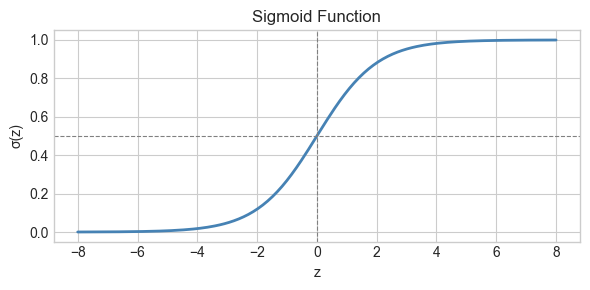

In [5]:
# Visualise sigmoid
z_vals = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3))
plt.plot(z_vals, sigmoid(z_vals), color='steelblue', linewidth=2)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('z')
plt.ylabel('σ(z)')
plt.title('Sigmoid Function')
plt.tight_layout()
plt.show()

## 8. Cost Function — Binary Cross-Entropy

In [6]:
def compute_cost(X, y, w, b):
    """
    Binary cross-entropy: J = -(1/m) * sum(y * log(y_hat) + (1-y) * log(1-y_hat)).

    A small epsilon is added inside log to prevent log(0).
    """
    m = X.shape[0]
    z     = X @ w + b
    y_hat = sigmoid(z)                                  # shape (m,)
    eps   = 1e-12
    J = -np.sum(y * np.log(y_hat + eps)
                + (1 - y) * np.log(1 - y_hat + eps)) / m
    return J

## 9. Gradient Computation

In [7]:
def compute_gradient(X, y, w, b):
    """
    dJ/dw = (1/m) * X^T @ (y_hat - y)   shape (n,)
    dJ/db = (1/m) * sum(y_hat - y)       scalar
    """
    m     = X.shape[0]
    y_hat = sigmoid(X @ w + b)    # shape (m,)
    errors = y_hat - y             # shape (m,)
    dw = (X.T @ errors) / m
    db = np.sum(errors) / m
    return dw, db

## 10. Gradient Descent

In [8]:
def gradient_descent(X, y, alpha, num_iters):
    n = X.shape[1]
    w = np.zeros(n)
    b = 0.0
    J_history = []

    for i in range(num_iters):
        dw, db = compute_gradient(X, y, w, b)
        w = w - alpha * dw
        b = b - alpha * db
        J_history.append(compute_cost(X, y, w, b))

        if i % 500 == 0:
            print(f"Iter {i:5d} | Cost: {J_history[-1]:.4f}")

    return w, b, J_history

## 11. Train the Model

In [9]:
alpha     = 0.5
num_iters = 3000

w, b, J_history = gradient_descent(X_train_n, y_train, alpha, num_iters)
print(f"\nLearned w = {w}, b = {b:.4f}")

Iter     0 | Cost: 0.5834
Iter   500 | Cost: 0.2160
Iter  1000 | Cost: 0.2160
Iter  1500 | Cost: 0.2160
Iter  2000 | Cost: 0.2160
Iter  2500 | Cost: 0.2160

Learned w = [2.84602869 2.36841245], b = -0.1170


## 12. Cost History Plot

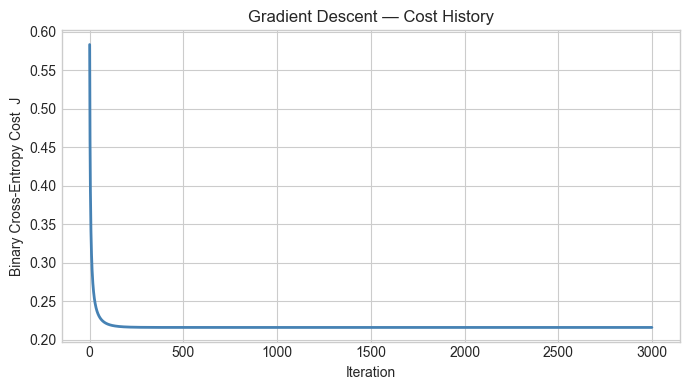

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(J_history, color='steelblue', linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('Binary Cross-Entropy Cost  J')
plt.title('Gradient Descent — Cost History')
plt.tight_layout()
plt.show()

## 13. Decision Boundary Visualisation

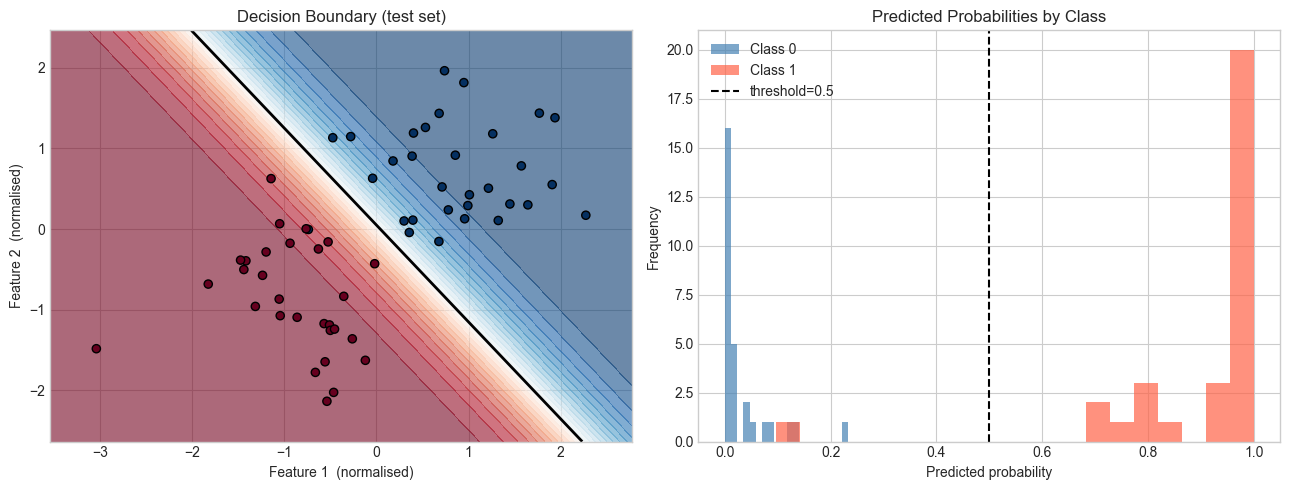

In [11]:
def predict(X, w, b, threshold=0.5):
    probs = sigmoid(X @ w + b)
    return (probs >= threshold).astype(int)

# Build a grid over the normalised feature space
x1_min, x1_max = X_test_n[:, 0].min() - 0.5, X_test_n[:, 0].max() + 0.5
x2_min, x2_max = X_test_n[:, 1].min() - 0.5, X_test_n[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                     np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
probs_grid = sigmoid(grid @ w + b).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Decision boundary ---
axes[0].contourf(xx, yy, probs_grid, levels=25, cmap='RdBu', alpha=0.6)
axes[0].contour(xx, yy, probs_grid, levels=[0.5], colors='black', linewidths=2)
scatter = axes[0].scatter(X_test_n[:, 0], X_test_n[:, 1],
                          c=y_test, cmap='RdBu', edgecolors='k', s=35)
axes[0].set_xlabel('Feature 1  (normalised)')
axes[0].set_ylabel('Feature 2  (normalised)')
axes[0].set_title('Decision Boundary (test set)')

# --- Probability histogram ---
probs_test = sigmoid(X_test_n @ w + b)
axes[1].hist(probs_test[y_test == 0], bins=20, alpha=0.7, color='steelblue', label='Class 0')
axes[1].hist(probs_test[y_test == 1], bins=20, alpha=0.7, color='tomato',    label='Class 1')
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='threshold=0.5')
axes[1].set_xlabel('Predicted probability')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Predicted Probabilities by Class')
axes[1].legend()

plt.tight_layout()
plt.show()

## 14. Evaluation Metrics

In [12]:
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[TN, FP], [FN, TP]])

def precision_recall_f1(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    precision = TP / (TP + FP + 1e-12)
    recall    = TP / (TP + FN + 1e-12)
    f1        = 2 * precision * recall / (precision + recall + 1e-12)
    return precision, recall, f1

y_pred_test = predict(X_test_n, w, b)

acc = accuracy(y_test, y_pred_test)
cm  = confusion_matrix(y_test, y_pred_test)
prec, rec, f1 = precision_recall_f1(y_test, y_pred_test)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"\nConfusion Matrix (rows=actual, cols=predicted):")
print(f"              Pred 0   Pred 1")
print(f"  Actual 0  {cm[0,0]:7d}  {cm[0,1]:7d}")
print(f"  Actual 1  {cm[1,0]:7d}  {cm[1,1]:7d}")

Accuracy  : 0.9833
Precision : 1.0000
Recall    : 0.9677
F1 Score  : 0.9836

Confusion Matrix (rows=actual, cols=predicted):
              Pred 0   Pred 1
  Actual 0       29        0
  Actual 1        1       30


## 15. Observations and Limitations

### What we observed
- The sigmoid squashes the linear score to a valid probability in (0, 1).
- Cost decreases smoothly — gradient descent converges.
- The decision boundary is a straight line (hyperplane) separating the two classes.
- High accuracy because the data was linearly separable.

### Limitations
| Limitation | Description |
|------------|-------------|
| **Linear boundary only** | Cannot separate non-linearly distributed classes (use SVM or neural nets). |
| **Sensitive to outliers** | A single misplaced point can shift the decision boundary. |
| **Binary only** | Requires extension (one-vs-rest) for multi-class problems. |
| **Assumes independence** | Correlated features can inflate or deflate coefficient estimates. |
| **Imbalanced classes** | Accuracy is misleading; prefer F1 or AUC-ROC on imbalanced data. |
